In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os
import warnings
warnings.filterwarnings('ignore')

try:
    pd.options.future.infer_string = False
except Exception:
    pass

try:
    font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = 'Cambria'
except Exception:
    plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 11

import platform
if platform.system() == 'Windows':
    base = r"C:\\Users\\sosoq\\Documents\\GitHub\\EdenCampus-PhD\\EdenCampus_PhD"
else:
    base = os.path.expanduser("~/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD")
for folder in ["01_data/weather", "01_data/demand",
               "04_results/figures", "04_results/tables"]:
    os.makedirs(os.path.join(base, folder), exist_ok=True)

# ── LOAD FULL-YEAR INPUTS FROM COMMITTED DATA (single source of truth) ──
# Demand from committed CSV, PV from committed 2023 weather CSV. No live PVGIS,
# no inline synthetic generation. See DATA_RECONCILIATION.md for provenance.
from data_prep import load_inputs

_inputs_fy = load_inputs(base, representative_weeks=False)

time_index_fy     = _inputs_fy["time_index"]
elec_demand_fy    = _inputs_fy["elec_demand"]
thermal_demand_fy = _inputs_fy["thermal_demand"]
pv_profile_fy     = _inputs_fy["pv_profile"]

print(f"Full year time index: {len(time_index_fy)} hours")
print(f"PV profile: peak={pv_profile_fy.max()*100:.1f}% | "
      f"non-zero hours={(pv_profile_fy > 0).sum()}")
print(f"Electrical demand: peak={elec_demand_fy.max():.0f} kW | "
      f"annual={elec_demand_fy.sum()/1000:.0f} MWh")
print(f"Thermal demand:    peak={thermal_demand_fy.max():.0f} kW | "
      f"annual={thermal_demand_fy.sum()/1000:.0f} MWh (MODELLED)")
print("\nFull year input data loaded from committed files!")


Eden Campus inputs loaded from committed data files
  Snapshots:            8760 h (full year)
  Elec demand peak:     681.6 kW
  Elec demand annual:   2400.9 MWh (full year)
  Thermal demand peak:  755.6 kW (MODELLED)
  PV peak:              92.7 % of 1000 kW
  PV annual (1 MW):     1029.7 MWh
Full year time index: 8760 hours
PV profile: peak=92.7% | non-zero hours=4289
Electrical demand: peak=682 kW | annual=2401 MWh
Thermal demand:    peak=756 kW | annual=1728 MWh (MODELLED)

Full year input data loaded from committed files!


In [2]:
# Capacity/demand charge on peak grid import (£/kW/yr). 0 disables.
GRID_CAPACITY_CHARGE = 120.0

def run_full_year_scenario(name, pv_profile, elec_demand,
                            thermal_demand, use_bess=False,
                            use_pcm=False, use_h2=False,
                            use_heatpump=False):
    print(f"  Running {name}...")
    n = pypsa.Network()
    n.set_snapshots(pv_profile.index)

    n.add("Carrier", "AC",       co2_emissions=0.233)
    n.add("Carrier", "hydrogen", co2_emissions=0.0)
    n.add("Carrier", "heat",     co2_emissions=0.0)

    n.add("Bus", "Electricity Bus", carrier="AC")
    if use_h2:
        n.add("Bus", "Hydrogen Bus", carrier="hydrogen")
    if use_pcm or use_heatpump:
        n.add("Bus", "Heat Bus", carrier="heat")

    n.add("Generator", "Solar PV",
          bus="Electricity Bus", p_nom=1000,
          p_max_pu=pv_profile, marginal_cost=0)
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", p_nom=2000,
          marginal_cost=0.280)  # £/kWh (280 £/MWh)
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", p_nom=500,
          p_max_pu=0, p_min_pu=-1, marginal_cost=-0.050)  # £/kWh (-50 £/MWh SEG)

    if use_bess:
        n.add("StorageUnit", "BESS",
              bus="Electricity Bus", p_nom=500, max_hours=4,
              efficiency_store=0.95, efficiency_dispatch=0.95,
              standing_loss=0.0002, cyclic_state_of_charge=True)

    if use_h2:
        n.add("Link", "Electrolyser",
              bus0="Electricity Bus", bus1="Hydrogen Bus",
              p_nom=200, efficiency=0.70, marginal_cost=0.001)  # £/kWh
        n.add("Link", "Fuel Cell",
              bus0="Hydrogen Bus", bus1="Electricity Bus",
              p_nom=100, efficiency=0.50, marginal_cost=0.002)  # £/kWh
        n.add("Store", "Hydrogen Tank",
              bus="Hydrogen Bus", e_nom=5000,
              e_cyclic=True, standing_loss=0.0001)

    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", p_set=elec_demand)

    if use_pcm or use_heatpump:
        n.add("Generator", "Backup Boiler",
              bus="Heat Bus", p_nom=600, marginal_cost=0.110)  # £/kWh (110 £/MWh)
        n.add("Load", "Thermal Demand",
              bus="Heat Bus", p_set=thermal_demand)
        if use_heatpump:
            n.add("Link", "Heat Pump",
                  bus0="Electricity Bus", bus1="Heat Bus",
                  p_nom=300, efficiency=3.0, marginal_cost=0.0005)  # £/kWh
        if use_pcm:
            n.add("StorageUnit", "PCM TES",
                  bus="Heat Bus", p_nom=200, max_hours=8,
                  efficiency_store=0.95, efficiency_dispatch=0.92,
                  standing_loss=0.001, cyclic_state_of_charge=True)

    # Capacity/demand charge on peak grid import (£/kW/yr) — realistic UK billing
    from capacity_charge import add_capacity_charge
    n.optimize.create_model()
    add_capacity_charge(n, GRID_CAPACITY_CHARGE, import_generator="Grid Import")
    n.optimize.solve_model(solver_name='highs')

    # ── Extract KPIs ──
    pv_gen       = n.generators_t.p["Solar PV"]
    grid_import  = n.generators_t.p["Grid Import"]
    grid_export  = n.generators_t.p["Grid Export"].abs()
    total_pv     = pv_gen.sum()
    total_demand = elec_demand.sum()
    total_import = grid_import.sum()
    total_export = grid_export.sum()
    pv_consumed  = total_pv - total_export
    self_consump = (pv_consumed / total_pv   * 100) if total_pv     > 0 else 0
    solar_frac   = (pv_consumed / total_demand * 100) if total_demand > 0 else 0
    peak_base    = elec_demand.max()
    peak_with    = grid_import.max()
    peak_red     = (peak_base - peak_with) / peak_base * 100
    co2_saved    = pv_consumed * 0.233 / 1000
    co2_grid     = total_import * 0.233 / 1000
    autonomy     = (1 - total_import / total_demand) * 100

    # ── Monthly breakdown ──
    monthly_pv     = pv_gen.resample('ME').sum()     / 1000
    monthly_import = grid_import.resample('ME').sum() / 1000
    monthly_demand = elec_demand.resample('ME').sum() / 1000

    print(f"    Solar={solar_frac:.1f}% | "
          f"CO2={co2_saved:.1f}t | "
          f"Cost=£{n.objective/1000:.0f}k | "
          f"Autonomy={autonomy:.1f}%")

    return {
        'kpis': {
            'Scenario':                  name,
            'Annual PV (MWh)':           round(total_pv     / 1000, 1),
            'Annual Demand (MWh)':       round(total_demand / 1000, 1),
            'Annual Grid Import (MWh)':  round(total_import / 1000, 1),
            'Annual Grid Export (MWh)':  round(total_export / 1000, 1),
            'Self-Consumption (%)':      round(self_consump,  1),
            'Solar Fraction (%)':        round(solar_frac,    1),
            'Energy Autonomy (%)':       round(autonomy,      1),
            'Peak Reduction (%)':        round(peak_red,      1),
            'CO2 Saved (tonnes/yr)':     round(co2_saved,     1),
            'CO2 from Grid (tonnes/yr)': round(co2_grid,      1),
            'Annual Cost (£k)':          round(n.objective / 1000, 1),
        },
        'monthly_pv':     monthly_pv,
        'monthly_import': monthly_import,
        'monthly_demand': monthly_demand,
        'network':        n,
    }

print("FULL YEAR SCENARIO COMPARISON — 8760 hours")
print("=" * 55)
print("Note: this will take 3-8 minutes — please wait...")
print()

scenarios_fy = [
    ("S0: PV Only",      False, False, False, False),
    ("S1: PV + BESS",    True,  False, False, False),
    ("S2: PV + PCM TES", False, True,  False, True),
    ("S3: PV + H2 LDES", False, False, True,  False),
    ("S4: Full Hybrid",  True,  True,  True,  True),
]

fy_results = {}
for name, bess, pcm, h2, hp in scenarios_fy:
    fy_results[name] = run_full_year_scenario(
        name, pv_profile_fy, elec_demand_fy,
        thermal_demand_fy, bess, pcm, h2, hp)

fy_kpis_df = pd.DataFrame(
    [v['kpis'] for v in fy_results.values()]).set_index('Scenario')

print("\n" + "=" * 55)
print("FULL YEAR KPI RESULTS")
print("=" * 55)
print(fy_kpis_df.to_string())

FULL YEAR SCENARIO COMPARISON — 8760 hours
Note: this will take 3-8 minutes — please wait...

  Running S0: PV Only...


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io:Writing objective.


Writing constraints.:   0%|          | 0/4 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 4/4 [00:00<00:00, 115.63it/s]

...

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 131401 primals, 306600 duals
Objective: 6.28e+05
Solver model: available
Solver message: Optimal



      70090     6.2842957767e+05 Pr: 0(0); Du: 0(1.10592e-07) 4.1s
      70090     6.2842957767e+05 Pr: 0(0); Du: 0(1.10592e-07) 4.1s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-3dzc1oe9
Model status        : Optimal
Simplex   iterations: 70090
Objective value     :  6.2842957767e+05
P-D objective error :  4.5756219368e-14
HiGHS run time      :          4.17


INFO:pypsa.optimization.optimize:The variable 'peak_import' could not be mapped to the network component because it does not include the symbol '-'.


INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Store-fix-e-lower, Store-fix-e-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance, peak_import_def were not assigned to the network.


    Solar=42.7% | CO2=238.8t | Cost=£628k | Autonomy=24.2%

FULL YEAR KPI RESULTS
                  Annual PV (MWh)  Annual Demand (MWh)  Annual Grid Import (MWh)  Annual Grid Export (MWh)  Self-Consumption (%)  Solar Fraction (%)  Energy Autonomy (%)  Peak Reduction (%)  CO2 Saved (tonnes/yr)  CO2 from Grid (tonnes/yr)  Annual Cost (£k)
Scenario                                                                                                                                                                                                                                                         
S0: PV Only                 764.0               2400.9                    1636.9                       0.0                 100.0                31.8                 31.8                 1.4                  178.0                      381.4             539.0
S1: PV + BESS               932.0               2400.9                    1495.6                       0.0                 100.0                

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


...

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


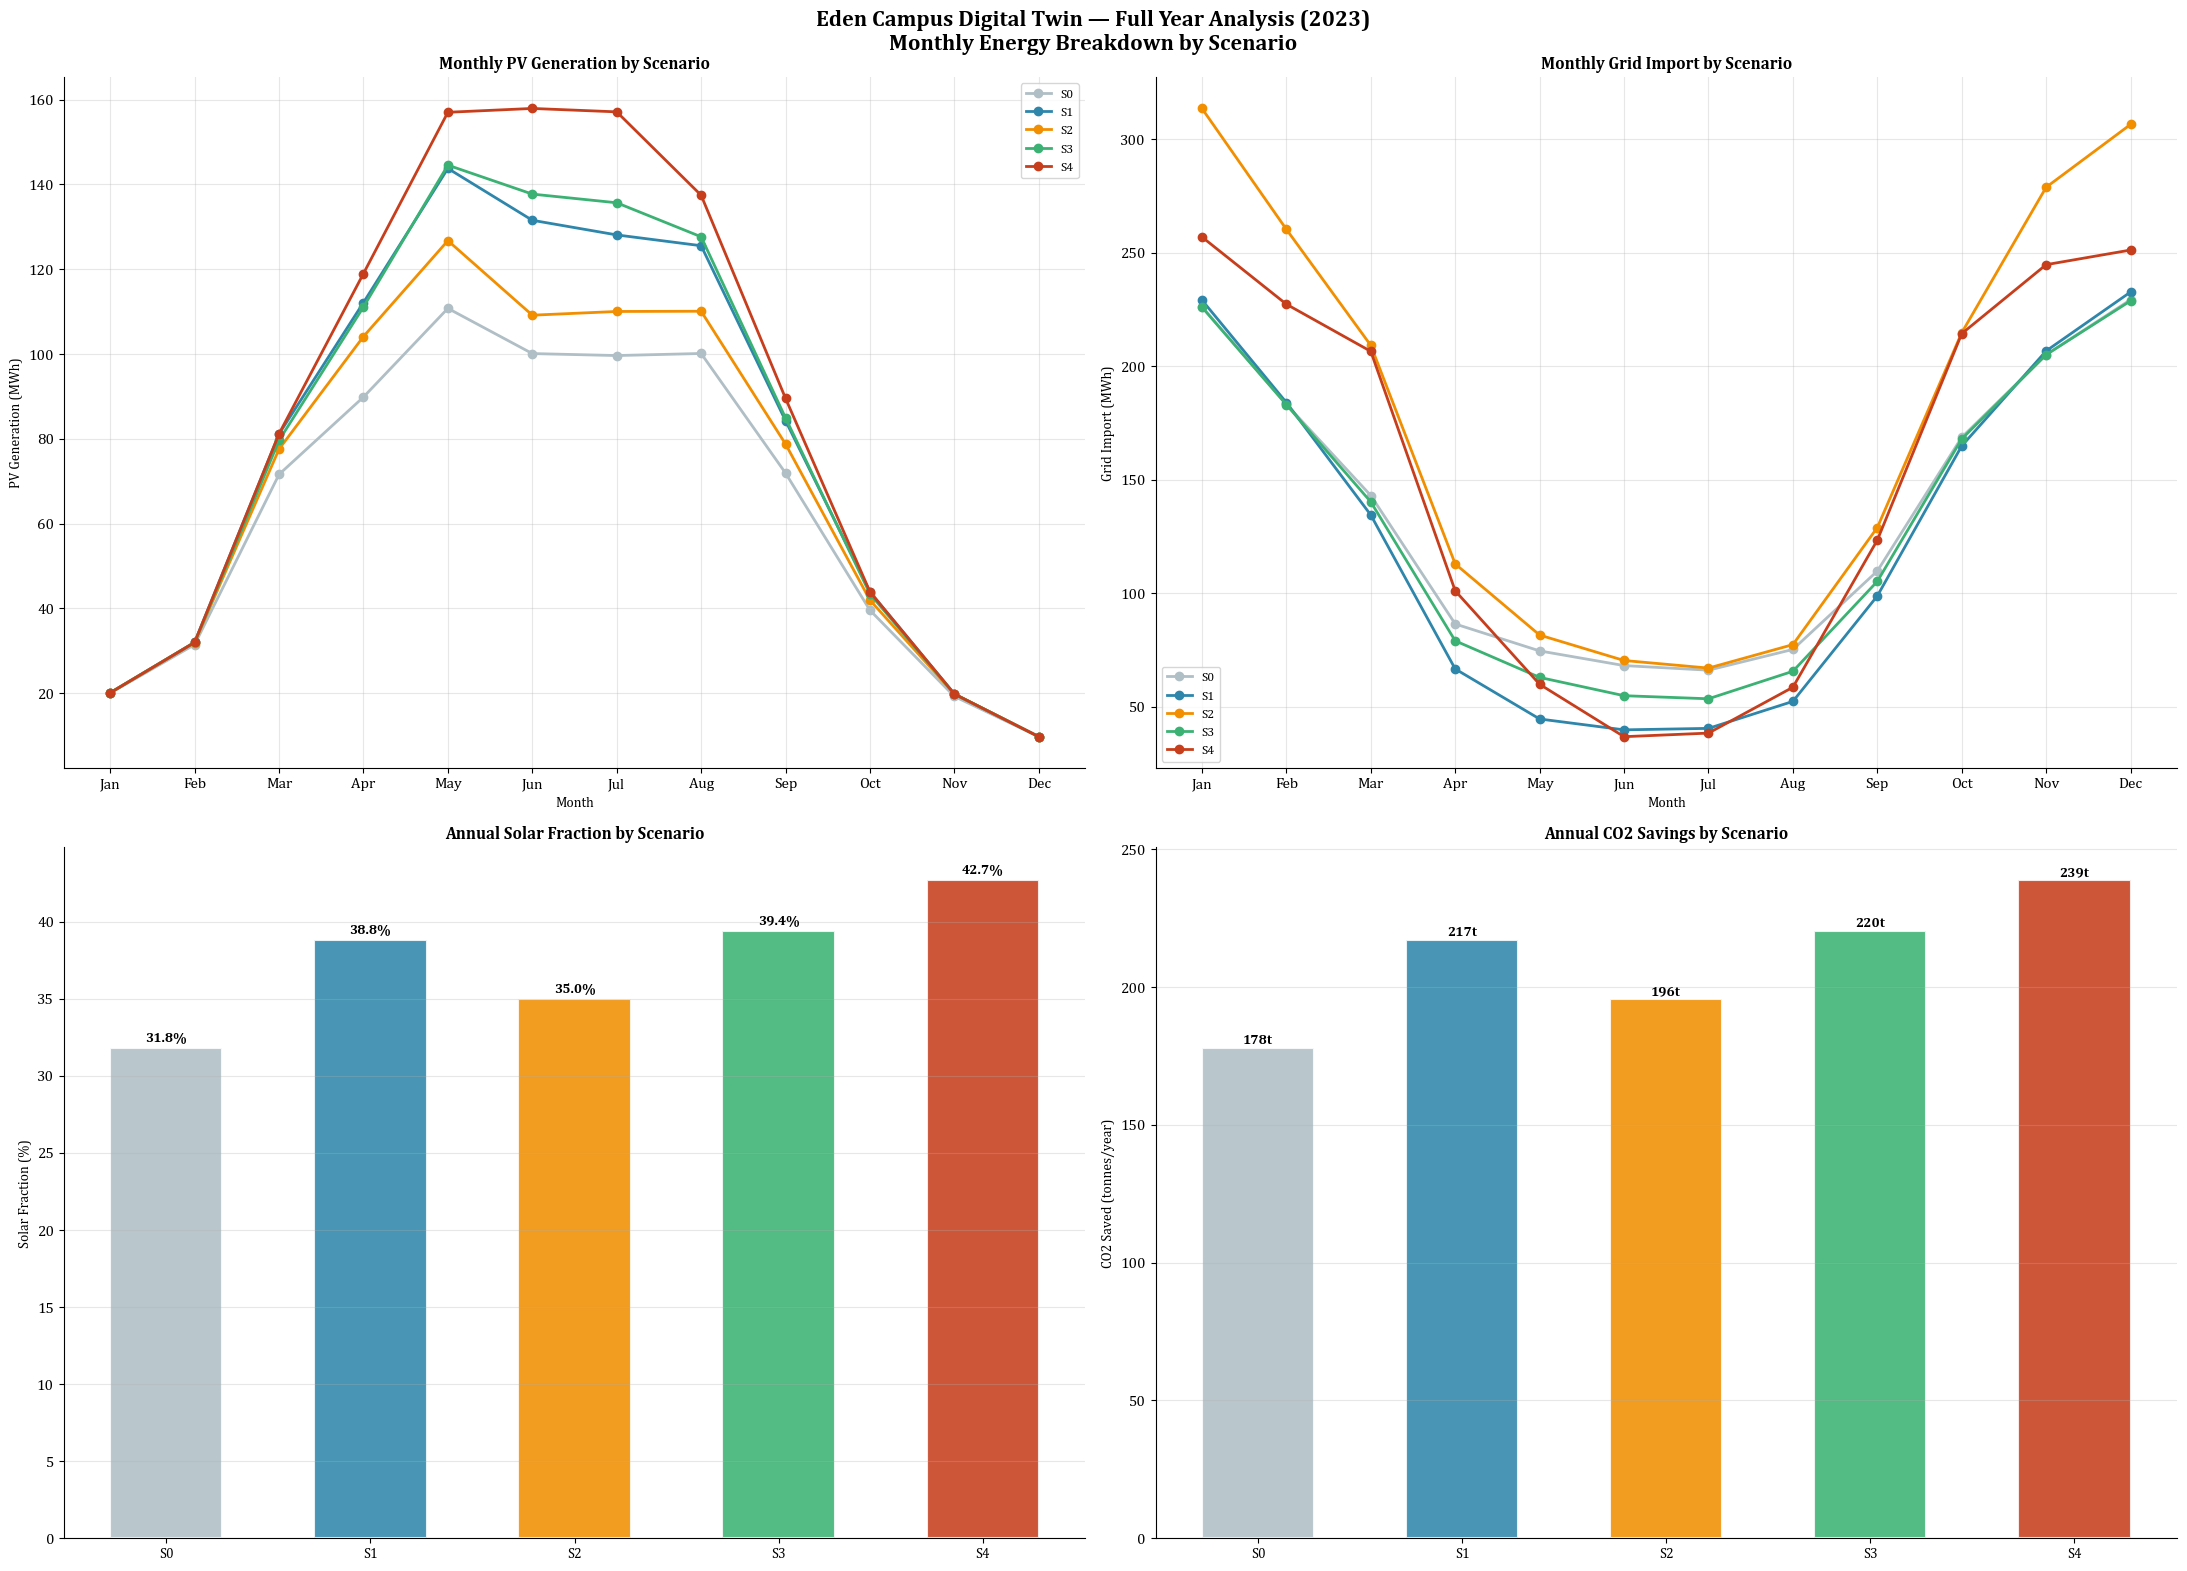

Full year analysis chart saved!


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(22, 16))
fig.suptitle(
    'Eden Campus Digital Twin — Full Year Analysis (2023)\n'
    'Monthly Energy Breakdown by Scenario',
    fontsize=16, fontweight='bold')

months      = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
colors_s    = ['#B0BEC5','#2E86AB','#F18F01','#3BB273','#C73E1D']
scenario_names = list(fy_results.keys())

# ── Monthly PV Generation ──
ax = axes[0, 0]
for i, name in enumerate(scenario_names):
    vals = fy_results[name]['monthly_pv'].values
    ax.plot(months, vals, color=colors_s[i],
            linewidth=2.0, marker='o', markersize=6,
            label=name.split(':')[0])
ax.set_title('Monthly PV Generation by Scenario',
             fontsize=12, fontweight='bold')
ax.set_ylabel('PV Generation (MWh)', fontsize=10)
ax.set_xlabel('Month', fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── Monthly Grid Import ──
ax = axes[0, 1]
for i, name in enumerate(scenario_names):
    vals = fy_results[name]['monthly_import'].values
    ax.plot(months, vals, color=colors_s[i],
            linewidth=2.0, marker='o', markersize=6,
            label=name.split(':')[0])
ax.set_title('Monthly Grid Import by Scenario',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Grid Import (MWh)', fontsize=10)
ax.set_xlabel('Month', fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── Annual KPI Bar Comparison ──
ax = axes[1, 0]
x     = np.arange(len(scenario_names))
width = 0.55
vals  = fy_kpis_df['Solar Fraction (%)'].values
bars  = ax.bar(x, vals, width, color=colors_s,
               edgecolor='white', linewidth=1.5, alpha=0.88)
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Annual Solar Fraction by Scenario',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([s.split(':')[0] for s in scenario_names],
                    fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── Annual CO2 Saved ──
ax = axes[1, 1]
vals = fy_kpis_df['CO2 Saved (tonnes/yr)'].values
bars = ax.bar(x, vals, width, color=colors_s,
              edgecolor='white', linewidth=1.5, alpha=0.88)
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            f'{val:.0f}t', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Annual CO2 Savings by Scenario',
             fontsize=12, fontweight='bold')
ax.set_ylabel('CO2 Saved (tonnes/year)', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([s.split(':')[0] for s in scenario_names],
                    fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "full_year_analysis.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Full year analysis chart saved!")

In [4]:
os.makedirs(os.path.join(base, "04_results/tables"), exist_ok=True)

# ── Excel ──
excel_path = os.path.join(base, "04_results/tables",
                           "full_year_scenario_comparison.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    fy_kpis_df.to_excel(writer, sheet_name='Annual KPIs')
    for name, res in fy_results.items():
        sheet = name[:3].replace(':', '').strip()
        monthly = pd.DataFrame({
            'PV (MWh)':     res['monthly_pv'].values,
            'Import (MWh)': res['monthly_import'].values,
            'Demand (MWh)': res['monthly_demand'].values,
        }, index=months)
        monthly.to_excel(writer, sheet_name=f'{sheet}_monthly')
print(f"Excel saved: {excel_path}")

# ── LaTeX ──
print("\n── Annual KPI LaTeX Table ──\n")
cols = ['Annual PV (MWh)', 'Annual Grid Import (MWh)',
        'Solar Fraction (%)', 'Energy Autonomy (%)',
        'CO2 Saved (tonnes/yr)', 'Annual Cost (£k)']
print(fy_kpis_df[cols].to_latex(
    caption='Full year annual KPI comparison across all five scenarios.',
    label='tab:full_year_kpis',
    float_format='{:.1f}'.format))

# ── Scale up to 20-year lifetime ──
# ── Corrected 20-Year Lifetime Projections ──
print("\n── 20-Year Lifetime Projections (corrected units) ──")
print(f"{'Scenario':<25} {'CO2 (tonnes)':>15} "
      f"{'Annual Saving vs S0 (£k)':>26} "
      f"{'20-yr Saving vs S0 (£k)':>25}")
print("-" * 90)

s0_cost = fy_kpis_df.loc['S0: PV Only', 'Annual Cost (£k)']
for name, row in fy_kpis_df.iterrows():
    co2_20yr      = row['CO2 Saved (tonnes/yr)'] * 20
    annual_saving = (s0_cost - row['Annual Cost (£k)']) / 1000
    saving_20yr   = annual_saving * 20
    print(f"  {name:<23} {co2_20yr:>12.0f}t "
          f"{annual_saving:>+22.1f}k "
          f"{saving_20yr:>+22.1f}k")

print("\nNote: costs are operational energy costs only.")
print("Capital costs of BESS, PCM and H2 equipment not included.")
print("Full techno-economic analysis (NPV, IRR) is Paper 2 scope.")

Excel saved: /Users/everythingkrypto/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD/04_results/tables/full_year_scenario_comparison.xlsx

── Annual KPI LaTeX Table ──

\begin{table}
\caption{Full year annual KPI comparison across all five scenarios.}
\label{tab:full_year_kpis}
\begin{tabular}{lrrrrrr}
\toprule
 & Annual PV (MWh) & Annual Grid Import (MWh) & Solar Fraction (%) & Energy Autonomy (%) & CO2 Saved (tonnes/yr) & Annual Cost (£k) \\
Scenario &  &  &  &  &  &  \\
\midrule
S0: PV Only & 764.0 & 1636.9 & 31.8 & 31.8 & 178.0 & 539.0 \\
S1: PV + BESS & 932.0 & 1495.6 & 38.8 & 37.7 & 217.2 & 468.0 \\
S2: PV + PCM TES & 840.0 & 2122.2 & 35.0 & 11.6 & 195.7 & 683.3 \\
S3: PV + H2 LDES & 946.3 & 1573.3 & 39.4 & 34.5 & 220.5 & 515.6 \\
S4: Full Hybrid & 1024.7 & 1820.1 & 42.7 & 24.2 & 238.8 & 628.4 \\
\bottomrule
\end{tabular}
\end{table}


── 20-Year Lifetime Projections (corrected units) ──
Scenario                     CO2 (tonnes)   Annual Saving vs S0 (£k)   20-yr Saving vs S0 (£k)